# Superstore Sales and Profit Trend analysis

This notebook explores how monthly sales, profit, and order volume changes over period. W track month-over-month and year-over-year sales changes, then check whether profit follows the same trajectory or not.

* **Data Source:** `orders_enriched.csv` (generated in Notebook 1).
* **Timeline:** Grouped by the calendar month of the `Order Date` rather than the `Ship Date`.

## 1. Loaded and validated the input created in notebook 1

In [1]:
from pathlib import Path

# Importing pandas for loading and analysing tabular data.
import numpy as np

# Import NumPy for numerical checks such as np.isclose().
import pandas as pd


# To find the directory from which the notebook is running.

CURRENT_DIR = Path.cwd()


# If the notebook is running from the notebooks folder, move one level upward to locate the main project folder.

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR


# Define input and output folder locations.

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

PROCESSED_DATA_DIR = (
    PROJECT_ROOT / "data" / "processed"
)

TABLES_DIR = (
    PROJECT_ROOT / "results" / "tables"
)

FIGURES_DIR = (
    PROJECT_ROOT / "results" / "figures"
)


# Create the output folders.


for folder in [
    PROCESSED_DATA_DIR,
    TABLES_DIR,
    FIGURES_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


In [2]:
orders_path = PROCESSED_DATA_DIR / "orders_enriched.csv"

orders = pd.read_csv(
    orders_path,
    usecols=["Order ID", "Order Date", "Sales", "Profit"],
    parse_dates=["Order Date"],
)

assert pd.api.types.is_datetime64_any_dtype(orders["Order Date"]), (
    "Order Date was not parsed as a date."
)
assert orders.notna().all().all(), "A required field contains missing values."
assert len(orders) == 10_194, "Unexpected number of product lines."
assert orders["Order ID"].nunique() == 5_111, "Unexpected number of orders."

orders.agg({"Order Date": ["min", "max"]})

,Order Date
min,2023-01-03
max,2026-12-30


## 2. Monthly sales, profit, and orders

In [3]:
monthly_performance = (
    orders.groupby(pd.Grouper(key="Order Date", freq="ME"))
    .agg(
        Total_sales=("Sales", "sum"),
        Total_profit=("Profit", "sum"),
        Unique_Orders=("Order ID", "nunique"),
    )
    .sort_index()
    .reset_index()
)

monthly_performance["Profit_Margin_percent"] = (
    100 * monthly_performance["Total_profit"] / monthly_performance["Total_sales"]
)

# To maintain chronological order.
expected_months = pd.date_range("2023-01-31", "2026-12-31", freq="ME")
assert pd.DatetimeIndex(monthly_performance["Order Date"]).equals(expected_months)

# Rechecking the monthly figures with the original table totals.
assert np.isclose(monthly_performance["Total_sales"].sum(), 2_326_534.3543)
assert np.isclose(monthly_performance["Total_profit"].sum(), 292_296.8146)
assert monthly_performance["Unique_Orders"].sum() == 5_111

monthly_performance.head(3)

,Order Date,Total_sales,Total_profit,Unique_Orders,Profit_Margin_percent
0,2023-01-31,14518.055,2539.3907,33,17.491260
1,2023-02-28,4519.892,862.3084,28,19.078075
2,2023-03-31,56933.909,693.4499,72,1.217991


## 3. MOM and YOY comparisons

In [4]:
sales = monthly_performance["Total_sales"]
profit = monthly_performance["Total_profit"]

monthly_performance["Sales_MoM_percent"] = (
    100 * sales.pct_change(periods=1, fill_method=None)
)
monthly_performance["Sales_YoY_percent"] = ( 100 * sales.pct_change(periods=12, fill_method=None)
)
monthly_performance["Profit_YoY_change"] = profit.diff(periods=12)

# Preview to check two months that tests different comparisons.
comparison_check = monthly_performance.loc[   monthly_performance["Order Date"].isin(
        pd.to_datetime(["2023-02-28", "2024-01-31"])
    ),
    ["Order Date", "Sales_MoM_percent", "Sales_YoY_percent", "Profit_YoY_change"],
]

comparison_check.round(2)

C:\Users\parth\AppData\Local\Temp\ipykernel_2604\4115751940.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  comparison_check.round(2)


,Order Date,Sales_MoM_percent,Sales_YoY_percent,Profit_YoY_change
1,2023-02-28,-68.87,NaN,NaN
12,2024-01-31,-74.36,27.17,-5729.19


## 4. Monthly sales trend using Two-series line chart

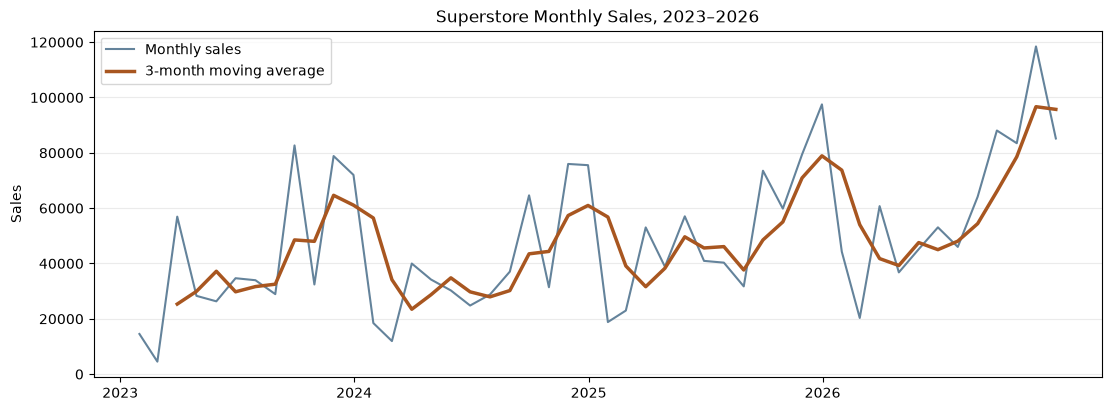

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

monthly_performance["Sales_3M_MA"] = (
    monthly_performance["Total_sales"].rolling(window=3).mean()
)

fig_sales, ax = plt.subplots(figsize=(11, 4), layout="constrained")

ax.plot(
    monthly_performance["Order Date"],
    monthly_performance["Total_sales"],
    color="#64839b",
    label="Monthly sales",
)
ax.plot(
    monthly_performance["Order Date"],
    monthly_performance["Sales_3M_MA"],
    color="#a85620",
    linewidth=2.5,
    label="3-month moving average",
)

ax.set(title="Superstore Monthly Sales, 2023–2026", ylabel="Sales")

# Show only those years for which the monthly sales data is available 
years = sorted(monthly_performance["Order Date"].dt.year.unique())
year_ticks = pd.to_datetime([f"{year}-01-01" for year in years])

ax.set_xticks(year_ticks, labels=[str(year) for year in years])
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

### Note
The blue line tracks actual monthly sales, while the red line shows a 3-month rolling average (averaging the current month with the two prior months) to smooth out short-term fluctuations and make the broader trend easier to spot. 
Since it requires three full months of data, the orange line begins in March 2023.

## 5. Monthly profit and loss Vertical bar chart

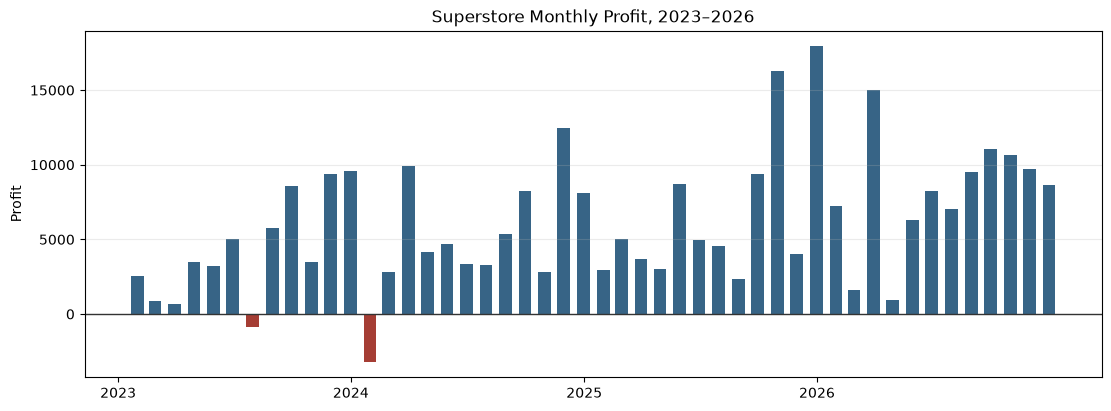

In [6]:
is_loss_month = monthly_performance["Total_profit"].lt(0)

fig_profit, ax = plt.subplots(figsize=(11, 4), layout="constrained")

ax.bar(
    monthly_performance["Order Date"],
    monthly_performance["Total_profit"],
    width=20,  # Bar width is represented in days
    color=np.where(is_loss_month, "#a53d34", "#376486"),
)

ax.axhline(0, color="#333333", linewidth=1)
ax.set(title="Superstore Monthly Profit, 2023–2026", ylabel="Profit")

years = sorted(monthly_performance["Order Date"].dt.year.unique())
year_ticks = pd.to_datetime([f"{year}-01-01" for year in years])

ax.set_xticks(year_ticks, labels=[str(year) for year in years])
ax.grid(axis="y", alpha=0.25)
plt.show()

### Note
Each bar represents a single month's total profit—bars above the zero line indicate profitable months, while the red bars dipping below zero highlight net losses. Only two months ended in the red:  July 2023 (−841.48) and January 2024(−3,189.80) . 

## 6. Why Rising Sales didn't translate into Profit

In [7]:
sales_up_profit_down = (
    monthly_performance.loc[
        monthly_performance["Sales_YoY_percent"].gt(0)
        & monthly_performance["Profit_YoY_change"].lt(0),
        ["Order Date", "Sales_YoY_percent", "Profit_YoY_change", "Total_profit"],
    ]
    .sort_values("Profit_YoY_change")
    .reset_index(drop=True)
)

comparable_months = monthly_performance["Sales_YoY_percent"].notna().sum()

print(f"{len(sales_up_profit_down)} of {comparable_months} comparable months")

sales_up_profit_down.style.format(
    {
        "Sales_YoY_percent": "{:+.2f}%",
        "Profit_YoY_change": "{:+,.2f}",
        "Total_profit": "{:,.2f}",
    }
)

7 of 36 comparable months


,Order Date,Sales_YoY_percent,Profit_YoY_change,Total_profit
0,2025-11-30 00:00:00,+4.53%,"-8,463.38","4,011.41"
1,2025-03-31 00:00:00,+32.65%,"-6,222.73","3,707.89"
2,2024-01-31 00:00:00,+27.17%,"-5,729.19","-3,189.80"
3,2026-10-31 00:00:00,+39.52%,"-5,586.31","10,670.53"
4,2024-12-31 00:00:00,+4.89%,"-1,461.59","8,093.06"
5,2025-04-30 00:00:00,+13.55%,"-1,195.84","2,991.66"
6,2024-08-31 00:00:00,+28.14%,-393.60,"5,371.63"


## 7. Export results

In [8]:
notebook_04_tables = TABLES_DIR / "notebook_04"
notebook_04_figures = FIGURES_DIR / "notebook_04"

for folder in (notebook_04_tables, notebook_04_figures):
    folder.mkdir(parents=True, exist_ok=True)

monthly_csv = notebook_04_tables / "monthly_performance.csv"
sales_png = notebook_04_figures / "monthly_sales_trend.png"
profit_png = notebook_04_figures / "monthly_profit.png"

monthly_performance.to_csv(monthly_csv, index=False, date_format="%Y-%m-%d")
fig_sales.savefig(sales_png, dpi=300, bbox_inches="tight")
fig_profit.savefig(profit_png, dpi=300, bbox_inches="tight")

for output_path in (monthly_csv, sales_png, profit_png):
    assert output_path.is_file() and output_path.stat().st_size > 0, output_path